In [1]:
import pandas as pd
import numpy as np

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("../Data/mpg.csv")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    object 
 8   name          398 non-null    object 
dtypes: float64(4), int64(3), object(2)
memory usage: 28.1+ KB


In [4]:
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


In [5]:
df.columns
df = df.drop(columns = ['name','origin'])

In [6]:
df['horsepower'] = df['horsepower'].fillna(df['horsepower'].median())


In [7]:
print(df.shape,"|",df.isna().sum().sum(),"missing values")

(398, 7) | 0 missing values


In [8]:
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year
0,18.0,8,307.0,130.0,3504,12.0,70
1,15.0,8,350.0,165.0,3693,11.5,70
2,18.0,8,318.0,150.0,3436,11.0,70
3,16.0,8,304.0,150.0,3433,12.0,70
4,17.0,8,302.0,140.0,3449,10.5,70


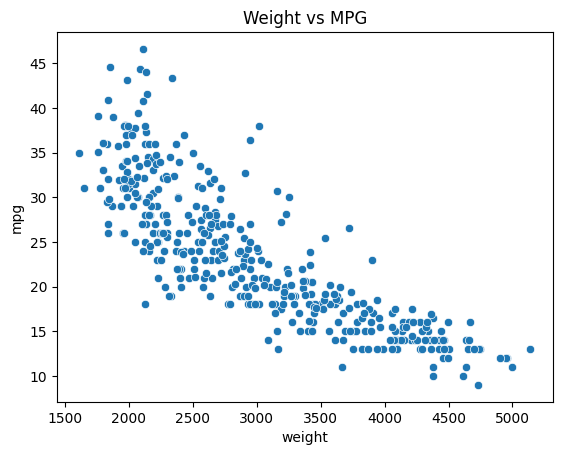

In [9]:
sns.scatterplot(data = df, x = 'weight', y ='mpg')
plt.title("Weight vs MPG")
plt.show()

In [10]:
x = df.drop(columns=['mpg'])
y = df['mpg']
print(x.shape, y.shape)

(398, 6) (398,)


In [11]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
print(x_train.shape, x_test.shape)

(318, 6) (80, 6)


In [12]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(x_train[["weight"]], y_train)

print("coef:     ", model.coef_)
print("intercept:", model.intercept_)

coef:      [-0.00780524]
intercept: 46.7820633664505


In [13]:
from sklearn.metrics import r2_score, mean_absolute_error

pred = model.predict(x_test[["weight"]])
print("weight only -> R2:", round(r2_score(y_test, pred), 3), "| MAE:", round(mean_absolute_error(y_test, pred), 2))

weight only -> R2: 0.723 | MAE: 3.12


In [14]:
# all six features
model_all = LinearRegression()
model_all.fit(x_train, y_train)
pred_all = model_all.predict(x_test)
print("all features -> R2:", round(r2_score(y_test, pred_all), 3), "| MAE:", round(mean_absolute_error(y_test, pred_all), 2))

all features -> R2: 0.824 | MAE: 2.47
